# A simple IPERLITE wildfire signal workflow

This example loads development-catalog IPERLITE L1C data over a small Namibia AOI, calculates four spectral indices, and compares a July median composite with an August scene using openEO processes. The dates are available acquisitions, not verified fire dates; treat the result as a demonstration of the workflow, not a confirmed burn map.

L1C contains top-of-atmosphere reflectance. This deliberately simple example does not apply atmospheric correction or cloud masking.

In [6]:
import openeo

connection = openeo.connect("openeo.terrascope.be").authenticate_oidc()

Authenticated using refresh token.


## 1. Select the area, dates, and bands

The selected Namibia polygon intersects three L1C acquisitions (July 6, July 12, and August 3, 2026). We use the two July scenes for the pre-fire median and the August scene for the post period. The selected RTOA bands are the nearest available wavelengths to those used by each index.

In [7]:
IPERLITE_L1C = "https://stac-api-dev.vgt.vito.be/collections/terrascope-iperlite-l1c-cog-v1"

# Small AOI in Namibia, covered by the July and August scenes.
aoi = {
    "type": "Polygon",
    "coordinates": [[
        [15.1741065, -23.6265988],
        [15.1741065, -23.5781422],
        [15.0532065, -23.5781422],
        [15.0532065, -23.6265988],
        [15.1741065, -23.6265988],
    ]],
}

pre_period = ["2026-07-06", "2026-07-13"]
post_period = ["2026-08-03", "2026-08-04"]

# RTOA bands nearest to 531, 550, 570, 665, 680, 705, 750, 783, and 842 nm.
bands = ["RTOA18", "RTOA23", "RTOA33", "RTOA52", "RTOA58", "RTOA66", "RTOA84", "RTOA101", "RTOA122"]
print(f"Pre-fire window: {pre_period}; post-fire window: {post_period}")

Pre-fire window: ['2026-07-06', '2026-07-13']; post-fire window: ['2026-08-03', '2026-08-04']


## 2. Load the selected L1C data

`load_stac` sends the spatial, temporal, and band selection to openEO. The subset is loaded for the AOI and date range instead of downloading complete scenes.

In [8]:
cube = connection.load_stac(
    url=IPERLITE_L1C,
    spatial_extent=aoi,
    temporal_extent=["2026-07-06", "2026-08-04"],
    bands=bands,
)
cube

In [10]:
# cube.execute_batch(title="cube loading")

## 3. Calculate four spectral indices

These indices were chosen to compare complementary vegetation signals using IPERLITE's VNIR bands: broad greenness, chlorophyll-sensitive red-edge response, short-term photosynthetic stress, and chlorophyll absorption depth. Together they are more informative than NDVI alone, while remaining simple band arithmetic.

- **NDVI** = (R842 - R665) / (R842 + R665): a familiar broad-band greenness baseline for vegetation change ([Tucker, 1979](https://doi.org/10.1016/0034-4257(79)90013-0)).
- **CIre** = R783 / R705 - 1: a red-edge chlorophyll proxy that complements NDVI, which can be less sensitive to chlorophyll differences in dense vegetation ([Gitelson et al., 2003](https://doi.org/10.1078/0176-1617-00887)). The wavelengths here are the nearest IPERLITE bands to the target wavelengths.
- **PRI** = (R531 - R570) / (R531 + R570): a signal associated with photosynthetic light-use efficiency and xanthophyll-cycle activity; it may respond to physiological stress, but is also sensitive to illumination and canopy conditions ([Gamon et al., 1992](https://doi.org/10.1016/0034-4257(92)90059-S)).
- **CAD680** = 1 - R680 / Rcontinuum: estimates the depth of the chlorophyll absorption feature near 680 nm relative to a local spectral baseline. Here, Rcontinuum is linearly interpolated between 550 and 750 nm. This is a simplified continuum-depth calculation used in this example. [Yang et al. (2006)](https://doi.org/10.1631/jzus.2006.A2002) discuss a related chlorophyll absorption continuum index; that paper is included as background, not as the source for this specific 550/750 nm implementation.

These are exploratory vegetation-change signals, not calibrated wildfire-severity measures. They also use L1C top-of-atmosphere reflectance, without atmospheric correction or cloud masking.

In [11]:
r531 = cube.band("RTOA18")
r550 = cube.band("RTOA23")
r570 = cube.band("RTOA33")
r665 = cube.band("RTOA52")
r680 = cube.band("RTOA58")
r705 = cube.band("RTOA66")
r750 = cube.band("RTOA84")
r783 = cube.band("RTOA101")
r842 = cube.band("RTOA122")


ndvi = ((r842 - r665) / (r842 + r665)).add_dimension(
    name="bands", label="NDVI", type="bands"
)
cire = (r783 / r705 - 1).add_dimension(
    name="bands", label="CIre", type="bands"
)
pri = ((r531 - r570) / (r531 + r570)).add_dimension(
    name="bands", label="PRI", type="bands"
)

continuum_680 = r550 + (r750 - r550) * (130 / 200)
cad680 = (1 - r680 / continuum_680).add_dimension(
    name="bands", label="CAD680", type="bands"
)

indices = ndvi.merge_cubes(cire).merge_cubes(pri).merge_cubes(cad680)
indices

In [12]:
indices.execute_batch(title="indices calculation")

0:00:00 Job 'j-2610131750064b3cb278009e4ff01603': send 'start'
0:00:16 Job 'j-2610131750064b3cb278009e4ff01603': created (progress 0%)
0:00:21 Job 'j-2610131750064b3cb278009e4ff01603': queued (progress 0%)
0:00:27 Job 'j-2610131750064b3cb278009e4ff01603': queued (progress 0%)
0:00:35 Job 'j-2610131750064b3cb278009e4ff01603': queued (progress 0%)
0:00:45 Job 'j-2610131750064b3cb278009e4ff01603': queued (progress 0%)
0:00:58 Job 'j-2610131750064b3cb278009e4ff01603': running (progress 6.9%)
0:01:13 Job 'j-2610131750064b3cb278009e4ff01603': running (progress 9.1%)
0:01:32 Job 'j-2610131750064b3cb278009e4ff01603': finished (progress 100%)


<BatchJob job_id='j-2610131750064b3cb278009e4ff01603'>

## 4. Compare pre- and post-period composites

`filter_temporal` selects each window, and `reduce_dimension` computes a per-pixel median over its acquisitions. Subtracting the pre composite from the post composite gives the change in each index.

In [13]:
pre_indices = indices.filter_temporal(pre_period).reduce_dimension(
    dimension="t", reducer="median"
)
post_indices = indices.filter_temporal(post_period).reduce_dimension(
    dimension="t", reducer="median"
)

change = (post_indices - pre_indices).rename_labels(
    dimension="bands",
    target=["dNDVI", "dCIre", "dPRI", "dCAD680"],
)
change

## 5. Export and inspect the change indices

Submit the resulting four-band cube as an openEO batch job. The NetCDF output can then be opened locally with xarray.

In [14]:
change.execute_batch(
    title="IPERLITE Namibia spectral index change",
    outputfile="iperlite_namibia_index_change.nc",
)

0:00:00 Job 'j-26101317523142caadeb64f02740b050': send 'start'
0:00:15 Job 'j-26101317523142caadeb64f02740b050': created (progress 0%)
0:00:20 Job 'j-26101317523142caadeb64f02740b050': queued (progress 0%)
0:00:27 Job 'j-26101317523142caadeb64f02740b050': queued (progress 0%)
0:00:35 Job 'j-26101317523142caadeb64f02740b050': queued (progress 0%)
0:00:45 Job 'j-26101317523142caadeb64f02740b050': queued (progress 0%)
0:00:57 Job 'j-26101317523142caadeb64f02740b050': queued (progress 0%)
0:01:13 Job 'j-26101317523142caadeb64f02740b050': running (progress 9.0%)
0:01:32 Job 'j-26101317523142caadeb64f02740b050': running (progress 11.6%)
0:01:56 Job 'j-26101317523142caadeb64f02740b050': running (progress 14.7%)
0:02:26 Job 'j-26101317523142caadeb64f02740b050': finished (progress 100%)


<BatchJob job_id='j-26101317523142caadeb64f02740b050'>

The `d` prefix means post minus pre. A negative `dCAD680`, for example, indicates a reduction in the 680 nm chlorophyll absorption feature. These signals can highlight spectral change, but interpreting them as fire effects requires independent fire information and care with clouds and other scene differences.

In [15]:
import xarray as xr

change_ds = xr.open_dataset("iperlite_namibia_index_change.nc")
change_ds

<xarray.Dataset> Size: 3MB
Dimensions:  (y: 272, x: 678)
Coordinates:
  * y        (y) float64 2kB -23.58 -23.58 -23.58 ... -23.63 -23.63 -23.63
  * x        (x) float64 5kB 15.05 15.05 15.05 15.05 ... 15.17 15.17 15.17 15.17
Data variables:
    crs      |S1 1B ...
    dNDVI    (y, x) float32 738kB ...
    dCIre    (y, x) float32 738kB ...
    dPRI     (y, x) float32 738kB ...
    dCAD680  (y, x) float32 738kB ...
Attributes:
    Conventions:  CF-1.9
    institution:  VITO Terrascope openEO API - 0.73.0a20.dev20260926+133
    description:  
    title:

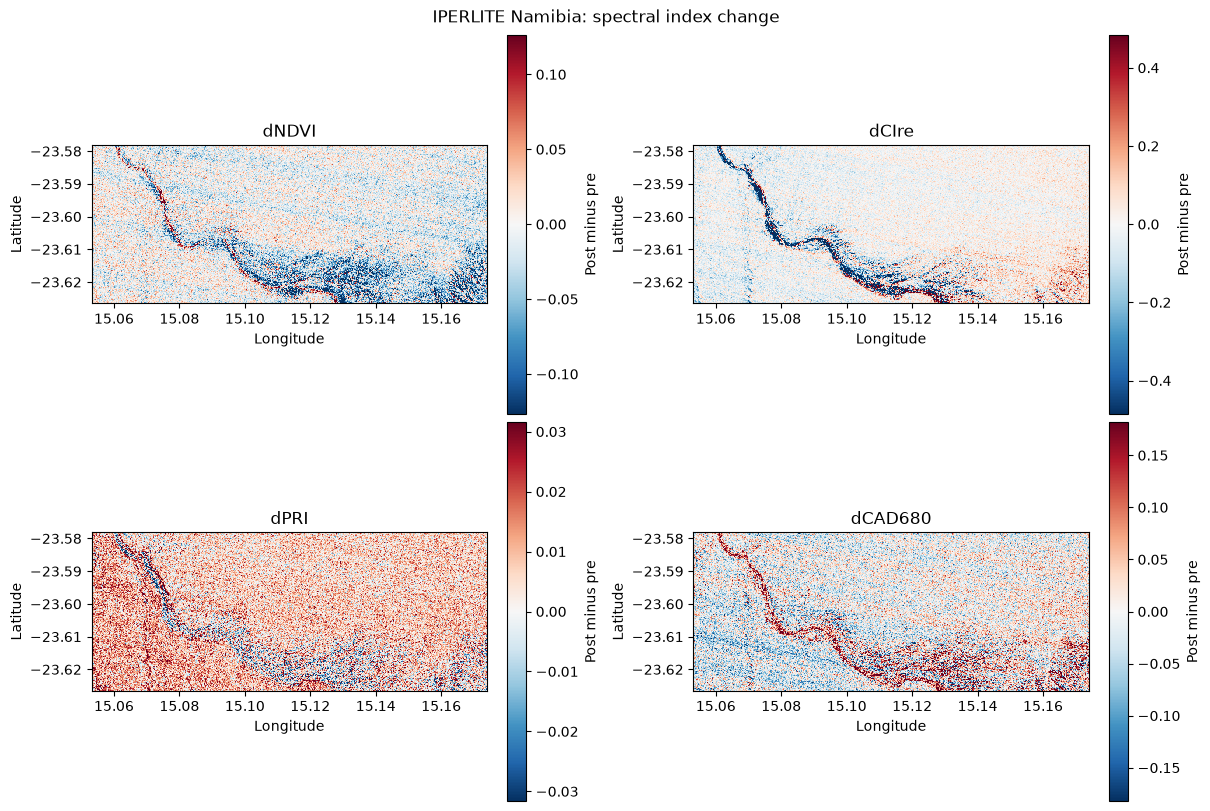

In [16]:
import matplotlib.pyplot as plt
import numpy as np

index_names = ["dNDVI", "dCIre", "dPRI", "dCAD680"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
extent = [
    float(change_ds.x.min()),
    float(change_ds.x.max()),
    float(change_ds.y.min()),
    float(change_ds.y.max()),
]

for ax, name in zip(axes.flat, index_names):
    values = change_ds[name].values
    limit = float(np.nanpercentile(np.abs(values), 98))
    if not np.isfinite(limit) or limit == 0:
        limit = 1e-6
    image = ax.imshow(
        values,
        extent=extent,
        origin="upper",
        cmap="RdBu_r",
        vmin=-limit,
        vmax=limit,
        interpolation="nearest",
    )
    ax.set_title(name)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    fig.colorbar(image, ax=ax, label="Post minus pre")

fig.suptitle("IPERLITE Namibia: spectral index change")
plt.show()

## Conclusion

The July-to-August comparison shows a narrow, branching feature with negative changes in NDVI and CIre, indicating reduced greenness and a changed red-edge signal in that area. PRI and CAD680 show more mixed changes. Together, these layers identify a spatially coherent spectral change worth investigating, but they do not establish that it was caused by fire.

This is a preliminary comparison of L1C top-of-atmosphere data with no cloud mask or atmospheric correction. Clouds, surface moisture, exposed soil, vegetation change, or scene-to-scene differences could also contribute. Each panel uses its own color scale, so color intensity should only be compared within a panel. Confirm a fire interpretation against an independent fire perimeter or incident record and, if available, cloud-free corrected imagery.